# **Import Libiraries**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error



# **Load Data**

In [6]:
df = sns.load_dataset("tips")
print(df.head())
print(df.info())
print(df.describe())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
None
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672


In [8]:
print(df.shape)
print(df.isnull().sum())
print(df.duplicated().sum())

(244, 7)
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
1


In [11]:
df = df.drop_duplicates()


# Split Data

In [12]:

X = df[["total_bill"]]
y = df["tip"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



# **Linear Regression Model**

In [13]:

model = LinearRegression()
model.fit(X_train, y_train)



LinearRegression()

# **Make Prediction**

In [14]:
y_pred = model.predict(X_test)



# **Evaluation**

In [15]:
mse= mean_squared_error(y_test, y_pred)
r2= r2_score(y_test ,y_pred)

print(f"Mean Squared Error: {mse:.3f}")
print (f"R**2 Score: {r2:.3f}")

Mean Squared Error: 1.151
R**2 Score: 0.528


# **Intercept and Coefficient**

In [16]:
print("Intercept: ",model.intercept_)
coefficients= pd.DataFrame(model.coef_, X.columns, columns=["Coefficient"])

Intercept:  1.035369320393141


# **Visiualization**

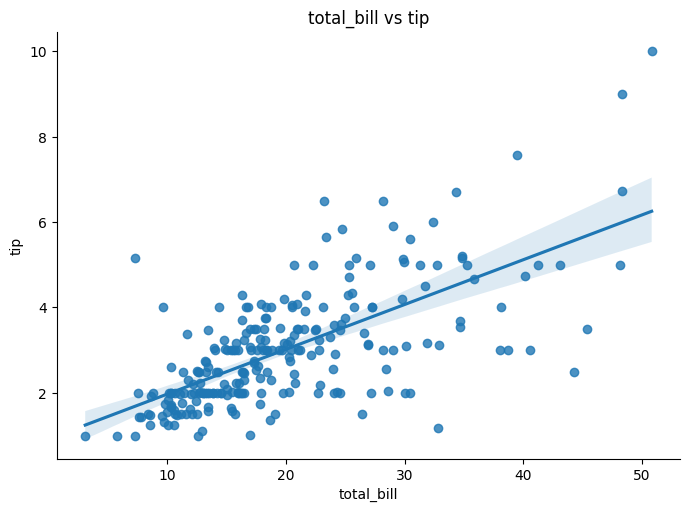

In [17]:
sns.lmplot(x="total_bill", y="tip", data=df, height=5, aspect=1.4)
plt.title("total_bill vs tip")
plt.show()